# Analiza danych przestrzennych - ćwiczenia laboratoryjne 2026/2027

Ten notatnik zalicza się do grupy zestawów zadań, na podstawie których odbywa się zaliczenie ćwiczeń i podlega zwrotowi do oceny w ustalonym na zajęciach terminie.

### Zasady uzupełniania i oceny notatnika
Uwagi i wytyczne ogólne dotyczące uzupełniania i oceny notatnika:
- Podczas wykonywania zadań należy korzystać wyłącznie z pakietów zaimportowanych na początku notatnika oraz z pakietów wchodzących w skład standardowej biblioteki Pythona, które można zaimportować samodzielnie we wskazanej komórce notatnika.
- Swoje rozwiązania należy wprowadzać wyłącznie w miejsce następujących fragmentów kodu:<br/> `# YOUR CODE HERE`<br/> `raise NotImplementedError()`<br/> 
a odpowiedzi tekstowe w komórkach oznaczonych hasłem:<br/> 
`YOUR ANSWER HERE`<br/> 
Nie należy w żaden sposób modyfikować pozostałych fragmentów kodu oraz innych elementów notatnika, w szczególności dodawać lub usuwać komórek oraz zmieniać nazwy pliku.
- Jeżeli zestaw zadań wymaga skorzystania z fragmentów kodu opracowanego w ramach wcześniejszych zestawów zadań, należy je umieścić we wskazanej komórce notatnika.
- Otrzymywane wyniki i odpowiedzi mają być rezultatem wykonania napisanego kodu, odpowiedzi uzupełniane manualnie nie podlegają ocenie.
- Zawarte w notatniku automatyczne testy mają charakter poglądowy. Dotyczą one wybranych aspektów zadań i mają na celu wykrywać podstawowe błędy. Przejście przez kod wszystkich testów nie oznacza, że zadanie jest wykonane w całości poprawnie i zostanie ocenione na maksymalną liczbę punktów.
- W przypadku wystąpienia ostrzeżenia należy przeanalizować jego przyczynę i odpowiednio poprawić kod. Nie należy wyciszać ostrzeżeń w celu ukrycia problemów w rozwiązaniu.
- Zadania, których rozwiązania powodują błędy przerywające wykonywanie kodu, nie podlegają ocenie.
- W treści niektórych zadań mogą znaleźć się przykładowe schematy ich rozwiązania lub przykładowe schematy istotnych części rozwiązania. Nie zawsze są to rozwiązania optymalne pod kątem długości kodu lub prostoty rozwiązania. Ich celem jest klarowne rozbicie pracy na kroki i ułatwienie samodzielnej weryfikacji wyników na każdym etapie. Należy je traktować wyłącznie poglądowo, a nie jako jedyne dopuszczalne rozwiązania. Ocenie podlega poprawność merytoryczna rozwiązania, jego kompletność oraz zgodność z wymaganiami, a nie konkretna forma zapisu.
- Dla zachowania przejrzystości i łatwego odnajdywania informacji w treści zadań podawane są pełne nazwy funkcji, metod i klas wraz z nazwami pakietów (np. `pandas.read_csv()`, `geopandas.GeoDataFrame.to_crs()`). W notatniku te same obiekty są dostępne przez skrótowe aliasy (np. `pd.read_csv()`, `gpd.GeoDataFrame.to_crs()`).

### Zasady wizualizacji wyników
Uwagi i wytyczne ogólne dotyczące wizualizacji wyników:
- Wszystkie wykresy powinny być wykonane w jednolitym, przejrzystym i czytelnym stylu, posiadać odpowiednio dobrane proporcje i zakresy wartości osi.
- Figury oraz obszary wykresów powinny mieć białe tło. Kolory napisów i pozostałych elementów należy dobrać tak, aby były czytelne na tym tle. Szerokość figury nie powinna przekraczać 20 cali.
- Każdy wykres powinien mieć tytuł. Osie powinny mieć opisy określające przedstawiane wielkości oraz ich jednostki, jeżeli mają zastosowanie. Jeżeli figura zawiera kilka wykresów, powinna mieć również wspólny tytuł. W przypadku map można wyłączyć widoczność osi zamiast je opisywać.

### Przed odesłaniem zestawu zadań do oceny
Przed odesłaniem zestawu zadań do oceny proszę uzupełnić komórkę z danymi autorów rozwiązania (nazwa zespołu oraz imiona, nazwiska i numery indeksów członków zespołu) oraz upewnić się, że notatnik działa zgodnie z oczekiwaniami. W tym celu należy skorzystać z opcji **Restart Kernel and Run All Cells...** dostępnej na górnej belce notatnika pod symbolem $\blacktriangleright\blacktriangleright$.

**Nazwa zespołu:** …

**Członkowie zespołu - imiona, nazwiska i numery indeksów:**

- …
- …
- …

---

## Zestaw zadań 2: Operacje geometryczne na wektorowych danych przestrzennych

In [3]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx
import shapely as shp

In [4]:
# Miejsce do importu pakietów wchodzących w skład standardowej biblioteki Pythona oraz ustawienie opcji wykorzystywanych pakietów

### Wczytanie danych

Poniższy kod wczytuje do zmiennych `rivers`, `cities`, `districts`, `voivodeships`, `administrative_centers` oraz `national_parks` dane z pliku `ZZ02_data.gpkg`.

Aby poprawnie wczytać dane, umieść plik `ZZ02_data.gpkg` w tym samym folderze, w którym znajduje się notatnik.

Dane są zapisane w układzie odniesienia EPSG:2180 i obejmują:

- `rivers` - geometrie liniowe wybranych rzek,
- `cities` - punktowe lokalizacje miast,
- `districts` - geometrie poligonowe powiatów,
- `voivodeships` - geometrie poligonowe województw,
- `administrative_centers` - punktowe lokalizacje ośrodków administracyjnych województw (w przypadku województw posiadających dwa ośrodki administracyjne punkt znajduje się w połowie odległości między nimi),
- `national_parks` - geometrie poligonowe parków narodowych.

In [5]:
rivers = gpd.read_file("ZZ02_data.gpkg", layer='rivers')
cities = gpd.read_file("ZZ02_data.gpkg", layer='cities')
districts = gpd.read_file("ZZ02_data.gpkg", layer='districts')
voivodeships = gpd.read_file("ZZ02_data.gpkg", layer='voivodeships')
administrative_centers = gpd.read_file("ZZ02_data.gpkg", layer='administrative_centers')
national_parks = gpd.read_file("ZZ02_data.gpkg", layer="national_parks")

### Uwagi dotyczące funkcji `buffer()`, `within()`, `covers()` i `intersects()`

Wszystkie te operacje są dostępne jako metody GeoPandas (np. `geopandas.GeoSeries.buffer()` oraz jako funkcje Shapely (np. `shapely.within()`). Shapely udostępnia również metody pojedynczych geometrii, (np. `shapely.geometry.polygon.Polygon.covers()`).

W dalszej części tego notatnika oraz w kolejnych zestawach zadań operacje te będą przywoływane po prostu jako `buffer()`, `within()`, `covers()` i `intersects()`, ponieważ mogą być wykonywane na różne sposoby, a wybór konkretnego wariantu zależy od przyjętej ścieżki rozwiązania zadania. Poszczególne wersje mogą jednak różnić się sposobem przekazywania argumentów oraz typem zwracanego wyniku.

#### Tworzenie stref przez `buffer()`
- Dodatnia odległość tworzy strefę wokół punktu, linii lub poligonu, a ujemna zmniejsza obszar poligonu. Dla punktów i linii niedodatnia odległość daje pustą geometrię.
- Odległość podaje się w jednostkach układu odniesienia, w którym wyrażone są poddawane operacji dane.
- W GeoPandas wynikiem jest `GeoSeries`. W Shapely buforowanie pojedynczej geometrii daje pojedynczą geometrię, a buforowanie wielu geometrii może zwracać tablicę geometrii. Buforowanie wielu geometrii nie scala automatycznie otrzymanych stref.

#### Sprawdzanie relacji przestrzennych za pomocą `within()`, `covers()` i `intersects()`
- Zwróć uwagę na kierunek porównania: `A.within(B)` lub `shapely.within(A, B)` sprawdza, czy geometria A znajduje się w obrębie geometrii B, natomiast `B.covers(A)` lub `shapely.covers(B, A)` sprawdza, czy geometria B obejmuje całą geometrię A.
- Funkcja `intersects()` sprawdza, czy dwie geometrie mają jakiekolwiek punkty wspólne. Uwzględnia również zetknięcie na granicy.
- W GeoPandas dwie serie `GeoSeries` są porównywane parami, domyślnie według indeksów. Argument `align=False` pozwala porównywać je według kolejności; serie muszą wtedy mieć tę samą długość. W Shapely porównywanie tablic geometrii odbywa się według pozycji elementów, bez wyrównywania indeksów.
- Przy porównaniu `GeoSeries` z pojedynczą geometrią Shapely każdy element serii jest porównywany z tym samym obiektem.
- Dla pojedynczych punktów porównywanych z poligonem `within()` wyklucza punkty leżące dokładnie na jego granicy, natomiast `covers()` je uwzględnia. Dla linii i poligonów samo dotknięcie granicy nie wyklucza wyniku `True` dla `within()`.

### Zadanie 1: Miasta blisko Wisły (5 pkt)

Korzystając z funkcji `buffer()` oraz `within()` lub `covers()`, sprawdź, które miasta leżą bliżej niż 20 km od Wisły oraz:
- zapisz geometrię strefy 20 km od Wisły do zmiennej `vistula_zone` jako jednowierszową serię danych `geopandas.GeoSeries`,
- zapisz wyniki sprawdzenia do tablicy `cities` w kolumnie `blisko Wisły` (True/False),
- oblicz liczbę miast leżących w tej strefie i zapisz wynik do zmiennej `cities_close_to_vistula`,
- korzystając z funkcji `print()`, wyświetl pełnym zdaniem informację, ile miast leży bliżej niż 20 km od Wisły,
- przygotuj wizualizację strefy oraz miast, wyróżniając kolorem miasta spełniające analizowane kryterium.

Wizualizacja powinna zawierać:
- województwa wypełnione jednolitym kolorem,
- strefę 20 km od Wisły z częściowo przezroczystym wypełnieniem,
- Wisłę w wyróżniającym się kolorze,
- punkty miast w jednym z dwóch wybranych kolorów w zależności od spełnienia analizowanego kryterium.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak, aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:
1) Korzystając z własności tablicy `pandas.DataFrame.loc` lub `pandas.DataFrame.iloc` albo z selekcji logicznej po kolumnie `rzeka`, wybierz dane dotyczące Wisły.
2) Korzystając z funkcji `buffer()`, przygotuj strefę sięgającą 20 km od Wisły. Zapisz wynik do zmiennej `vistula_zone` jako jednowierszową serię `geopandas.GeoSeries` w układzie EPSG:2180. Najprościej wykonać tę operację bezpośrednio na serii geometrii Wisły, dzięki czemu wynik zachowa odpowiedni typ danych i układ odniesienia.
3) Korzystając z funkcji `within()` lub `covers()`, porównaj punkty miast z geometrią utworzonej strefy. W tym przypadku najwygodniejsze jest porównanie całej serii punktów z pojedynczą geometrią strefy. Zwróć uwagę na kierunek porównania, zależny od wybranej funkcji. Wynik zapisz w kolumnie `blisko Wisły` tablicy `cities`.
4) Korzystając z funkcji `numpy.sum()`, policz miasta spełniające kryterium jako sumę wartości przygotowanej kolumny (w operacji sumowania True = 1, False = 0). Wynik zapisz do zmiennej `cities_close_to_vistula`.
5) Wyświetl wynik zgodnie z instrukcją i przygotuj mapę.

Uwagi do wykonania zadania:
- Dla warunku odległości ściśle mniejszej niż 20 km bardziej odpowiednia jest funkcja `within()`, ponieważ wyklucza punkty leżące dokładnie na granicy strefy. W dostarczonym zbiorze danych użycie `within()` lub `covers()` daje jednak ten sam wynik.

In [6]:
Wisla = rivers.iloc[[17]]
WIsla = Wisla.geometry
vistula_zone = Wisla.buffer(20000)
print(vistula_zone)
cities_geo = cities.geometry
cities["blisko Wisły"] = cities_geo.within(vistula_zone.iloc[0]) 
cities_close_to_vistula = np.sum( cities["blisko Wisły"])

17    POLYGON ((427077.966 597346.143, 427677.068 59...
dtype: geometry


In [7]:
# Komórka testowa
assert type(vistula_zone) == gpd.GeoSeries, "Zmienna vistula_zone powinna zawierać obiekt geopandas.GeoSeries."
assert len(vistula_zone) == 1, "Zmienna vistula_zone powinna zawierać jedną geometrię strefy wokół Wisły."
assert vistula_zone.crs == "epsg:2180", "Geometria strefy wokół Wisły nie jest wyrażona w układzie odniesienia EPSG:2180."
assert np.allclose(vistula_zone.total_bounds, [422633.13, 177392.15, 727213.75, 741600.61], rtol=0, atol=25,), "Zakres wartości współrzędnych strefy wokół Wisły nie odpowiada założeniom."
assert np.isclose(vistula_zone.area.iloc[0], 37205771587.84452, rtol=0.005), "Niepoprawne pole strefy wokół Wisły"

assert "blisko Wisły" in cities.columns, "W tablicy cities brakuje kolumny blisko Wisły."
assert cities["blisko Wisły"].dtype == bool, "Kolumna blisko Wisły powinna zawierać wartości logiczne True/False."
assert cities["blisko Wisły"].sum() == 161, "Niepoprawna liczba wartości True w kolumnie 'blisko Wisły'."

assert isinstance(cities_close_to_vistula, (int, np.integer)), "Zmienna cities_close_to_vistula powinna zawierać pojedynczą całkowitą liczbę miast."
assert cities_close_to_vistula == 161, "Niepoprawna liczba miast leżących bliżej niż 20 km od Wisły."

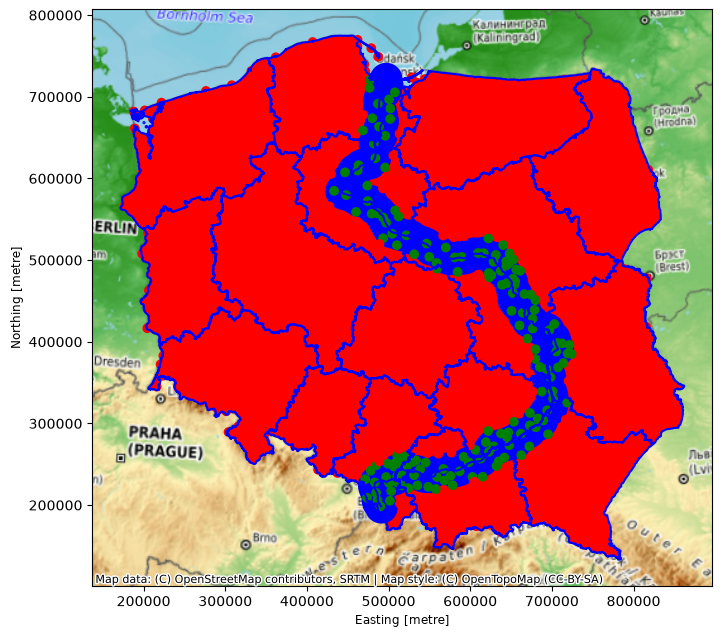

In [8]:
fig, ax = plt.subplots(1,1, figsize=(8,8))

voivodeships.boundary.plot(ax = ax, color = "blue")
voivodeships.plot(ax = ax, color = "red")
Wisla.plot(ax = ax, color = "blue")
vistula_zone.plot(ax = ax, color = "blue")
colors = np.where(cities["blisko Wisły"], "green", "red")
cities.plot(ax= ax, color = colors)

cx.add_basemap( ax = ax, crs="EPSG:2180", source ="OpenTopoMap", zoom =6, zorder =0)



### Zadanie 2: Województwa, przez które przepływa Odra (5 pkt)

Korzystając z funkcji `intersects()`, sprawdź, przez które województwa przepływa Odra oraz:
- zapisz wyniki do tablicy `voivodeships` w kolumnie `Odra w obrębie` (True/False),
- zapisz nazwy województw spełniających warunek do zmiennej `voivodeships_with_oder` jako listę,
- korzystając z funkcji `print()`, wyświetl pełnym zdaniem informację, przez które województwa przepływa Odra,
- przygotuj wizualizację, na której wskazane województwa będą wyróżnione kolorem.

Wizualizacja powinna zawierać:
- województwa wypełnione jednym z dwóch wybranych kolorów w zależności od spełnienia analizowanego kryterium,
- punkty miast w jednolitym kolorze,
- Odrę w wyróżniającym się kolorze.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:
1) Korzystając z własności tablicy `pandas.DataFrame.loc` lub `pandas.DataFrame.iloc` albo z selekcji logicznej po kolumnie `rzeka`, wybierz dane dotyczące Odry.
2) Korzystając z funkcji `intersects()`, sprawdź, które województwa przecinają się z geometrią Odry. Najwygodniejsze jest porównanie całej serii geometrii województw z pojedynczą geometrią Odry. Wynik zapisz do kolumny `Odra w obrębie` tablicy `voivodeships`.
3) Korzystając z własności tablicy `pandas.DataFrame.loc` lub `pandas.DataFrame.iloc`, selekcji logicznej po kolumnie `Odra w obrębie` oraz z funkcji `pandas.Series.to_list()`, zapisz nazwy województw spełniających warunek do zmiennej `voivodeships_with_oder`.
4) Wyświetl wynik zgodnie z instrukcją i przygotuj mapę.

In [9]:
Odra = rivers.geometry.iloc[11]
voivodeships["Odra w obrębie"] = woj.intersects(Odra)
voivodeships_with_oder = voivodeships.loc[voivodeships["Odra w obrębie"], "wojewodztwo"].to_list()


NameError: name 'woj' is not defined

In [ ]:
# Komórka testowa
assert "Odra w obrębie" in voivodeships.columns, "W tablicy voivodeships brakuje kolumny Odra w obrębie."
assert voivodeships["Odra w obrębie"].dtype == bool, "Kolumna Odra w obrębie powinna zawierać wartości logiczne True/False."

_expected_voivodeships_with_oder = ["dolnośląskie", "lubuskie", "opolskie", "zachodniopomorskie", "śląskie"]
assert sorted(voivodeships_with_oder) == sorted(_expected_voivodeships_with_oder), "Niepoprawna lista województw, przez które przepływa Odra."
assert voivodeships["Odra w obrębie"].eq(voivodeships["wojewodztwo"].isin(_expected_voivodeships_with_oder)).all(), "Niepoprawnie wskazano województwa w kolumnie Odra w obrębie."

assert sorted(voivodeships.loc[voivodeships["Odra w obrębie"], "wojewodztwo"]) == sorted(voivodeships_with_oder), "Lista voivodeships_with_oder nie odpowiada wynikom zapisanym w kolumnie Odra w obrębie."

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (8,8))


colors = np.where(voivodeships["Odra w obrębie"], "green", "red")
voivodeships.boundary.plot(ax = ax, color = "blue")
voivodeships.plot(ax = ax, color = colors)
cx.add_basemap(ax = ax, crs = "EPSG:2180", source = "OpenTopoMap", zoom = 6)

Odra = rivers.iloc[[11]]
Odra.plot(ax=ax, color = "blue")



### Zadanie 3: Długość Wisły w obrębie województwa mazowieckiego (3 pkt)

Korzystając z funkcji `geopandas.clip()` lub metody `geopandas.GeoSeries.clip()`) oraz z właściwości `geopandas.GeoSeries.length`, zmierz długość Wisły w obrębie województwa mazowieckiego oraz:
- zapisz długość w metrach do zmiennej `length_masovian`,
- korzystając z funkcji `print()`, wyświetl pełnym zdaniem informację o długości Wisły w obrębie tego województwa, podając wynik w kilometrach z dokładnością do trzech miejsc po przecinku.

Przykładowy schemat rozwiązania:
1) Korzystając z własności tablicy `pandas.DataFrame.loc` lub `pandas.DataFrame.iloc` albo z selekcji logicznej, wybierz z tablic `rivers` i `voivodeships` wiersze dotyczące Wisły i województwa mazowieckiego.
2) Korzystając z funkcji `geopandas.clip()` lub metody `geopandas.GeoSeries.clip()`, przytnij geometrię Wisły do granic województwa mazowieckiego.
3) Zmierz długość otrzymanej geometrii za pomocą właściwości `geopandas.GeoSeries.length`. Zapisz wynik w metrach jako pojedynczą liczbę do zmiennej `length_masovian`.
4) Wyświetl wynik zgodnie z instrukcją.

In [ ]:
Wisla = rivers.iloc[[17]]
mazowieckie = voivodeships.iloc[[6]]
przyciete = gpd.clip(Wisla, mazowieckie)


print(Wisla)
print(mazowieckie)
length_masovian = przyciete.to_crs(epsg=2180).length
length_masovian = length_masovian.iloc[0]
print(f"Długość Wisły z obrębie województwa Mazowieckiego wynosi {length_masovian:.3f} ")


In [ ]:
# Komórka testowa
assert isinstance(length_masovian, (float, np.floating)), "Zmienna length_masovian powinna zawierać pojedynczą liczbę, a nie serię danych lub tablicę."
assert np.isclose(length_masovian, 268751.31952529954, rtol=0, atol=0.01), "Niepoprawna długość Wisły w obrębie województwa mazowieckiego."

### Zadanie 4: Maksymalna odległość od granicy parku narodowego (3 pkt)

Korzystając z funkcji `geopandas.GeoSeries.maximum_inscribed_circle()`, oblicz maksymalną odległość punktu w obrębie każdego parku narodowego od jego granicy oraz:
- zapisz odległości w kilometrach do tablicy `national_parks`, w kolumnie `dystans maksymalny`,
- wskaż park z największą taką odległością oraz jej wartość; wyniki zapisz odpowiednio do zmiennych `deepest_park` i `max_distance`,
- korzystając z funkcji `print()`, wyświetl pełnym zdaniem nazwę wskazanego parku i maksymalną odległość od jego granicy, podając wartość w kilometrach z dokładnością do dwóch miejsc po przecinku.

Przykładowy schemat rozwiązania:
1) Korzystając z funkcji `geopandas.GeoSeries.maximum_inscribed_circle()`, wyznacz odcinki odpowiadające promieniom największych okręgów wpisanych w geometrie parków. Ustaw wartość argumentu `tolerance` na `10` (tolerancja obliczeń wynosząca 10 jednostek układu, w którym wyrażone są dane).
2) Zmierz długości otrzymanych odcinków za pomocą właściwości `geopandas.GeoSeries.length`, przelicz je na kilometry i zapisz w kolumnie `dystans maksymalny` tablicy `national_parks`.
3) Korzystając z funkcji `pandas.Series.idxmax()`, znajdź indeks parku o największej odległości.
4) Korzystając z wyznaczonego indeksu, odczytaj nazwę parku oraz odległość i zapisz je odpowiednio do zmiennych `deepest_park` i `max_distance`.
5) Wyświetl wynik zgodnie z instrukcją.

In [15]:
circles = national_parks.maximum_inscribed_circle(tolerance = 10)
national_parks["dystans maksymalny"] = (circles.length)/1000
#print(national_parks)

max = national_parks["dystans maksymalny"].idxmax()
print(max)
national_parks.iloc[4]
#print(national_parks)
deepest_park = national_parks.iloc[4, 0]
max_distance = national_parks.iloc[4, 2]

print(f"Park, którego maksymalna odległość od granicy osiągnęła największą wartość, to {deepest_park}, a ta maksymalna odlełośc wynosi: {max_distance:.2f}")

print(national_parks)



4
Park, którego maksymalna odległość od granicy osiągnęła największą wartość, to Kampinoski Park Narodowy, a ta maksymalna odlełośc wynosi: 5.67
                                            park  \
0                     Roztoczański Park Narodowy   
1                     Park Narodowy Ujście Warty   
2                      Białowieski Park Narodowy   
3                  Park Narodowy Bory Tucholskie   
4                       Kampinoski Park Narodowy   
5                        Pieniński Park Narodowy   
6                         Magurski Park Narodowy   
7                       Tatrzański Park Narodowy   
8                         Ojcowski Park Narodowy   
9                       Narwiański Park Narodowy   
10                   Park Narodowy Gór Stołowych   
11                         Poleski Park Narodowy   
12  Babiogórski Park Narodowy z siedzibą w Zawoi   
13                    Wielkopolski Park Narodowy   
14                       Słowiński Park Narodowy   
15                     

In [ ]:
# Komórka testowa
assert "dystans maksymalny" in national_parks.columns, "W tablicy national_parks brakuje kolumny dystans maksymalny."
_distances = national_parks["dystans maksymalny"]
assert pd.api.types.is_numeric_dtype(_distances), "Kolumna dystans maksymalny powinna zawierać liczby."
assert np.allclose(_distances.agg(["min", "mean", "max"]), [1.253923, 3.018636, 5.666187], rtol=0, atol=0.01,), "Niepoprawne minimum, średnia lub maksimum wyznaczonych odległości."

assert deepest_park == "Kampinoski Park Narodowy", "Niepoprawnie wskazano park o największej odległości od granicy."
assert np.isclose(max_distance, 5.666187, rtol=0, atol=0.01), "Niepoprawna wartość max_distance."

### Zadanie 5: Parki narodowe z centroidem poza swoim obszarem (3 pkt)

Korzystając z właściwości `geopandas.GeoSeries.centroid` oraz z funkcji `within()` lub `covers()`, sprawdź, w których parkach narodowych centroid leży poza ich obszarem oraz:
- zapisz nazwy tych parków do zmiennej `parks_with_centroid_outside` jako listę,
- korzystając z funkcji `print()`, wyświetl pełnym zdaniem informację, ile parków narodowych ma centroid poza swoim obszarem.

Przykładowy schemat rozwiązania:
1) Korzystając z właściwości `geopandas.GeoSeries.centroid`, wyznacz centroidy parków i zapisz je do zmiennej.
2) Korzystając z funkcji `within()` lub `covers()`, sprawdź, czy centroidy znajdują się w obrębie odpowiadających im parków narodowych. W tym przypadku najwygodniejsze jest porównanie parami dwóch serii geometrii. Zwróć uwagę na kierunek porównania oraz prawidłowe przyporządkowanie centroidów do parków. Zaneguj otrzymany wynik operatorem `~`, aby wskazać centroidy leżące poza obszarem parku.
3) Korzystając z własności `pandas.DataFrame.loc`, `pandas.DataFrame.iloc` lub selekcji logicznej oraz z funkcji `pandas.Series.to_list()`, zapisz nazwy wskazanych parków do zmiennej `parks_with_centroid_outside`.
4) Wyświetl wynik zgodnie z instrukcją.

Uwagi do wykonania zadania:
- Funkcja `covers()` uwzględnia również centroidy położone dokładnie na granicy parku, dlatego może być bardziej odpowiednia do sprawdzenia, czy centroid znajduje się poza jego obszarem. W dostarczonym zbiorze danych użycie `within()` lub `covers()` daje ten sam wynik.


In [25]:
national_parks_centroid = national_parks.centroid
parks_with_centroid = np.where(national_parks_centroid.within(national_parks.iloc[:,1]) == False)
#parks_with_centroid_outside = parks_with_centroid_outside.to_list()
parks_with_centroid_outside = national_parks.iloc[[0,6,9,15,20,22]]
parks_with_centroid_outside = parks_with_centroid_outside["park"].to_list()

In [26]:
# Komórka testowa
assert type(parks_with_centroid_outside) == list, "Zmienna parks_with_centroid_outside powinna zawierać listę nazw parków narodowych."
assert len(parks_with_centroid_outside) == 6, "Niepoprawna liczba parków narodowych z centroidem poza ich obszarem. Oczekiwano 6 parków."
assert set(parks_with_centroid_outside) == {
    "Roztoczański Park Narodowy",
    "Magurski Park Narodowy",
    "Narwiański Park Narodowy",
    "Karkonoski Park Narodowy",
    "Świętokrzyski Park Narodowy",
    "Drawieński Park Narodowy",
}, "Niepoprawna lista parków narodowych z centroidem poza ich obszarem."

### Zadanie 6: Obszary najbliższe centrum administracyjnym województw (6 pkt)

Korzystając z funkcji `shapely.voronoi_polygons()`, podziel obszar Polski na 16 części według odległości w linii prostej do punktów reprezentujących centra administracyjne województw, zapisanych w tablicy `administrative_centers` oraz:
- przygotuj i wyświetl tablicę `voronoi_areas` z geometriami komórek Voronoi przyciętych do obszaru Polski,
- przygotuj wizualizację otrzymanych obszarów oraz punktów centrów administracyjnych.

Tablica `voronoi_areas`:
> Indeks:<br>
> Domyślne indeksowanie tablicy komórek Voronoi.

> Kolumny: geometry<br>
> Kolumna zawierająca geometrie komórek Voronoi przyciętych do obszaru Polski.

Wizualizacja powinna zawierać:
- komórki Voronoi z wypełnieniem w różnych kolorach, z widocznymi granicami,
- granice województw (bez wypełnienia),
- punktowe oznaczenia centrów administracyjnych w wyróżniającym się kolorze.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:
1) Korzystając z operacji `union_all()`, scal i zapisz do osobnych zmiennych geometrie województw oraz centrów administracyjnych. Najwygodniej wykonać tę operację na seriach geometrii w GeoPandas - `geopandas.GeoDataFrame.geometry.union_all()`.
2) Przekaż połączone punkty do funkcji `shapely.voronoi_polygons()`. Jako wartość argumentu `extend_to` przekaż połączone geometrie województw, do których prostokątnej obwiedni mają zostać rozciągnięte komórki diagramu.
3) Wykorzystaj własność `shapely.geometry.collection.GeometryCollection.geoms` do pozyskania geometrii utworzonych komórek. Skonwertuj je do listy i wykorzystaj ją do utworzenia tablicy `geopandas.GeoDataFrame` o nazwie `voronoi_areas`. Pamiętaj o ustawieniu odpowiedniego układu odniesienia.
4) Korzystając z funkcji `geopandas.clip()` lub metody `geopandas.GeoSeries.clip()`, przytnij komórki Voronoi do połączonych geometrii województw.
5) Wyświetl przygotowaną tablicę i przygotuj wizualizację.

In [31]:
administrative_centers_geo = administrative_centers.geometry.union_all()
voivodeships_geo = voivodeships.geometry.union_all()
administrative_centers.shapely.voronoi_polygons(extend_to = voivodeships_geo)


AttributeError: 'GeoDataFrame' object has no attribute 'shapely'

In [ ]:
# Komórka testowa
assert type(voronoi_areas) == gpd.GeoDataFrame, "Zmienna voronoi_areas powinna zawierać obiekt geopandas.GeoDataFrame."
assert voronoi_areas.shape == (len(administrative_centers), 1), "Oczekiwano jednej komórki Voronoi dla każdego z 16 centrów administracyjnych oraz jednej kolumny."
assert list(voronoi_areas.columns) == ["geometry"], "Tablica voronoi_areas powinna zawierać wyłącznie kolumnę geometry."
assert voronoi_areas.crs == "epsg:2180", "Geometrie komórek Voronoi nie są wyrażone w układzie odniesienia EPSG:2180."
assert voronoi_areas.geometry.notna().all() and not voronoi_areas.is_empty.any(), "Tablica voronoi_areas zawiera puste lub brakujące geometrie."
assert np.allclose(voronoi_areas.total_bounds, [171698.71, 133223.35, 861895.76, 774917.37], rtol=0, atol=0.01,), "Zakres wartości współrzędnych komórek Voronoi nie odpowiada obszarowi Polski."
assert np.isclose(voronoi_areas.area.min(), 11045610196.28944), "Niepoprawne minimalne pole komórki Voronoi, wyrażone w metrach kwadratowych."
assert np.isclose(voronoi_areas.area.mean(), 19481145113.70406), "Niepoprawne średnie pole komórek Voronoi, wyrażone w metrach kwadratowych."
assert np.isclose(voronoi_areas.area.max(), 25673473772.23182), "Niepoprawne maksymalne pole komórki Voronoi, wyrażone w metrach kwadratowych."

In [ ]:
# Wizualizacja
# YOUR CODE HERE
raise NotImplementedError()